# Bài 5 (Trang 9) – Neural Network dự đoán doanh thu kinh doanh game

**Họ tên:** Mai Quốc Đại — **MSSV:** 6451071013 — **Lớp:** CQ.64.CNTT

## Câu a) Đọc dữ liệu train và test

In [1]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
import os
import numpy as np
import pandas as pd
pd.set_option("display.width", 140)
import matplotlib.pyplot as plt
import keras
from keras.models import Sequential, load_model
from keras.layers import Input, Dense
from keras.callbacks import ModelCheckpoint, LambdaCallback
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
tf.get_logger().setLevel("ERROR")  # ẩn cảnh báo không có GPU
keras.utils.set_random_seed(42)
train_df = pd.read_csv("data/sales_data_training.csv")
test_df = pd.read_csv("data/sales_data_test.csv")
print("Train:", train_df.shape, "- Test:", test_df.shape)
print(train_df.head())

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT


Train: (1000, 10) - Test: (400, 10)
   critic_rating  is_action  is_exclusive_to_us  is_portable  is_role_playing  is_sequel  is_sports  suitable_for_kids  total_earnings  \
0            3.5          1                   0            1                0          1          0                  0          132717   
1            4.5          0                   0            0                0          1          1                  0           83407   
2            3.0          0                   0            0                0          1          1                  0           62423   
3            4.5          1                   0            0                0          0          0                  1           69889   
4            4.0          1                   0            1                0          1          0                  1          161382   

   unit_price  
0       59.99  
1       49.99  
2       49.99  
3       39.99  
4       59.99  


## Câu b) Tách thuộc tính cần dự đoán total_earnings

In [2]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
X_train_raw = train_df.drop(columns=["total_earnings"]).values
y_train_raw = train_df[["total_earnings"]].values
X_test_raw = test_df.drop(columns=["total_earnings"]).values
y_test_raw = test_df[["total_earnings"]].values
print("Các thuộc tính đầu vào:", list(train_df.drop(columns=["total_earnings"]).columns))
print("X_train:", X_train_raw.shape, "y_train:", y_train_raw.shape)
print("X_test:", X_test_raw.shape, "y_test:", y_test_raw.shape)

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT
Các thuộc tính đầu vào: ['critic_rating', 'is_action', 'is_exclusive_to_us', 'is_portable', 'is_role_playing', 'is_sequel', 'is_sports', 'suitable_for_kids', 'unit_price']
X_train: (1000, 9) y_train: (1000, 1)
X_test: (400, 9) y_test: (400, 1)


## Câu c) Chuyển dữ liệu về [0,1]
Scaler được fit trên tập train và áp dụng cho tập test (tránh rò rỉ dữ liệu).

In [3]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
x_scaler = MinMaxScaler(feature_range=(0, 1))
y_scaler = MinMaxScaler(feature_range=(0, 1))
X_train_all = x_scaler.fit_transform(X_train_raw)
y_train_all = y_scaler.fit_transform(y_train_raw)
X_test = x_scaler.transform(X_test_raw)
y_test = y_scaler.transform(y_test_raw)
print("X_train min/max:", X_train_all.min(), X_train_all.max())
print("y_train min/max:", y_train_all.min(), y_train_all.max())
print("y_test  min/max:", round(y_test.min(), 4), round(y_test.max(), 4))

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT
X_train min/max: 0.0 1.0
y_train min/max: 0.0 1.0000000000000002
y_test  min/max: 0.018 0.8905


## Câu d) Chia train/validation tỷ lệ 8:2

In [4]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
X_train, X_val, y_train, y_val = train_test_split(X_train_all, y_train_all, test_size=0.2, random_state=42)
print("Train:", X_train.shape, "- Validation:", X_val.shape)

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT
Train: (800, 9) - Validation: (200, 9)


## Câu e) Xây dựng và biên dịch mô hình

In [5]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
model = Sequential([
    Input(shape=(9,)),
    Dense(50, activation="relu"),
    Dense(100, activation="relu"),
    Dense(50, activation="relu"),
    Dense(1),
])
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
              loss="mean_squared_error", metrics=["mean_absolute_error"])
model.summary()

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 50)             │           500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 100)            │         5,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 50)             │         5,050 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,701 (41.80 KB)

 Trainable params: 10,701 (41.80 KB)

 Non-trainable params: 0 (0.00 B)

## Câu f, g) Huấn luyện 100 epoch, in train_loss/val_loss mỗi epoch và lưu model tốt nhất (val_loss thấp nhất)

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT


Epoch   1: train_loss = 0.046354 - val_loss = 0.009827
Epoch   2: train_loss = 0.007237 - val_loss = 0.002921


Epoch   3: train_loss = 0.002524 - val_loss = 0.001127
Epoch   4: train_loss = 0.001224 - val_loss = 0.000683


Epoch   5: train_loss = 0.000699 - val_loss = 0.000464
Epoch   6: train_loss = 0.000444 - val_loss = 0.000347


Epoch   7: train_loss = 0.000303 - val_loss = 0.000276
Epoch   8: train_loss = 0.000226 - val_loss = 0.000230


Epoch   9: train_loss = 0.000179 - val_loss = 0.000200
Epoch  10: train_loss = 0.000146 - val_loss = 0.000183


... (31 outputs left out)

Epoch  91: train_loss = 0.000019 - val_loss = 0.000120
Epoch  92: train_loss = 0.000018 - val_loss = 0.000125


Epoch  93: train_loss = 0.000018 - val_loss = 0.000122
Epoch  94: train_loss = 0.000018 - val_loss = 0.000125
Epoch  95: train_loss = 0.000018 - val_loss = 0.000127


Epoch  96: train_loss = 0.000019 - val_loss = 0.000127
Epoch  97: train_loss = 0.000019 - val_loss = 0.000123
Epoch  98: train_loss = 0.000019 - val_loss = 0.000119


Epoch  99: train_loss = 0.000022 - val_loss = 0.000110
Epoch 100: train_loss = 0.000024 - val_loss = 0.000108

Model tốt nhất ở epoch 42, val_loss = 0.000098
Đã lưu vào models/best_sales_model.keras


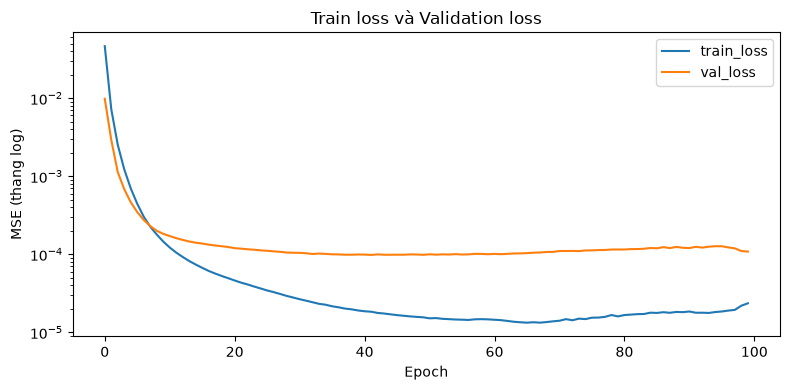

In [6]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
os.makedirs("models", exist_ok=True)
checkpoint = ModelCheckpoint("models/best_sales_model.keras", monitor="val_loss",
                             save_best_only=True, mode="min", verbose=0)
in_loss = LambdaCallback(on_epoch_end=lambda epoch, logs: print(
    f"Epoch {epoch + 1:3d}: train_loss = {logs['loss']:.6f} - val_loss = {logs['val_loss']:.6f}"))
history = model.fit(X_train, y_train, epochs=100, validation_data=(X_val, y_val),
                    callbacks=[checkpoint, in_loss], verbose=0)
best_epoch = int(np.argmin(history.history["val_loss"])) + 1
print(f"\nModel tốt nhất ở epoch {best_epoch}, val_loss = {min(history.history['val_loss']):.6f}")
print("Đã lưu vào models/best_sales_model.keras")

plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="train_loss")
plt.plot(history.history["val_loss"], label="val_loss")
plt.yscale("log"); plt.xlabel("Epoch"); plt.ylabel("MSE (thang log)"); plt.legend()
plt.title("Train loss và Validation loss"); plt.tight_layout(); plt.show()

## Câu h) Đánh giá Loss và Accuracy trên tập test
Đây là bài toán hồi quy nên "accuracy" được thể hiện qua MAE và hệ số xác định R² (mức độ mô hình giải thích được biến thiên của doanh thu).

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT


Test loss (MSE, thang [0,1]): 0.000104
Test MAE (thang [0,1])     : 0.005876
MAE theo đơn vị gốc ($)  : 1,589.38
RMSE theo đơn vị gốc ($) : 2,753.75
R² (accuracy hồi quy)     : 0.9965

5 mẫu test đầu tiên:
    Thực tế   Dự đoán
0   247537  249703.0
1    73960   74574.0
2    82671   82155.0
3   137456  138005.0
4    89639   89349.0


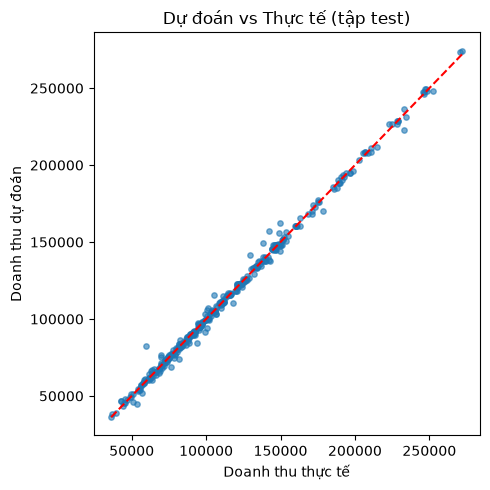

In [7]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
best_model = load_model("models/best_sales_model.keras")
test_loss, test_mae = best_model.evaluate(X_test, y_test, verbose=0)
print(f"Test loss (MSE, thang [0,1]): {test_loss:.6f}")
print(f"Test MAE (thang [0,1])     : {test_mae:.6f}")

y_pred = y_scaler.inverse_transform(best_model.predict(X_test, verbose=0))
print(f"MAE theo đơn vị gốc ($)  : {mean_absolute_error(y_test_raw, y_pred):,.2f}")
print(f"RMSE theo đơn vị gốc ($) : {np.sqrt(mean_squared_error(y_test_raw, y_pred)):,.2f}")
print(f"R² (accuracy hồi quy)     : {r2_score(y_test_raw, y_pred):.4f}")

so_sanh = pd.DataFrame({"Thực tế": y_test_raw.ravel(), "Dự đoán": y_pred.ravel().round(0)}).head(5)
print("\n5 mẫu test đầu tiên:\n", so_sanh)

plt.figure(figsize=(5, 5))
plt.scatter(y_test_raw, y_pred, s=15, alpha=0.6)
lim = [y_test_raw.min(), y_test_raw.max()]
plt.plot(lim, lim, "r--"); plt.xlabel("Doanh thu thực tế"); plt.ylabel("Doanh thu dự đoán")
plt.title("Dự đoán vs Thực tế (tập test)"); plt.tight_layout(); plt.show()